# Home Credit Default Risk – v6: predicted EXT scores + repeat customers + loan-product encoding + LightGBM + CatBoost
Run every cell from top to bottom (**Runtime → Run all**). On Colab's free CPU this takes roughly **50–70 minutes** (CatBoost is the slow part). Keep the browser tab open while it runs.

**Validation results (5-fold CV AUC, same folds for every model):**

| Version | What changed | CV AUC |
|---|---|---|
| v1 | LightGBM, 52 features | 0.7613 |
| v2 | + CatBoost blend, 3 LightGBM seeds | 0.7629 |
| v3 | + Optuna-tuned LightGBM | 0.7632 |
| v4 | + loan-product encoding | 0.7694 |
| v5 | + repeat-customer features | 0.7720 |
| **v6** | **+ model-predicted EXT_SOURCE_1 / EXT_SOURCE_3 (this notebook)** | **0.7733** |

| Model in this notebook | CV AUC |
|---|---|
| LightGBM (3 seeds) | 0.7715 |
| CatBoost | 0.7718 |
| **Blend: 50% LightGBM + 50% CatBoost** | **0.7733** |

All random seeds are fixed so the results can be reproduced, as the rules require. Only `train.csv` and `test.csv` are used (no external data), and every prediction comes from a model.

## The three key ideas

### 1. The loan product tells you the bank's risk price (from v4)
`AMT_CREDIT / AMT_ANNUITY` is roughly "how many payments" the loan has, and together with the interest rate it identifies the **loan product**.
The bank gives **higher interest rates to customers it considers riskier**, so the exact ratio carries the bank's own risk assessment (for example, ratio 20.56 has a 22.7% default rate and ratio 23.60 has 5.0%).
Tree models struggle to isolate such narrow exact values, so we add **target encoding**: each ratio value is replaced by the average default rate of training customers with the same value.

### 2. Some customers appear more than once (new in v5)
The data has no customer ID, but a customer who applied for several loans can still be recognised:
**a person's age (in days) at a life event does not change between two applications**, even when they are made on different dates.

| Value | Meaning |
|---|---|
| `a = DAYS_ID_PUBLISH − DAYS_BIRTH` | age when the ID document was issued |
| `b = DAYS_REGISTRATION − DAYS_BIRTH` | age at registration |
| `c = DAYS_EMPLOYED − DAYS_BIRTH` | age when the current job started |
| `p = DAYS_LAST_PHONE_CHANGE − DAYS_BIRTH` | age at the last phone change |

Two rows are **linked** ("probably the same customer") when they have the same gender and agree on **at least three of these four ages**. About 2.5% of all rows are linked to another row this way.
Requiring three ages matters: pairs that agree on only two ages turned out to be mostly coincidences (the results of their loans are unrelated), so they are left out. Each link has a `strength` (3 or 4 ages agree).

What happened to the customer's **other** loan is a strong signal: when it defaulted, this loan defaults far more often (the table in Step 6 shows the numbers).

### 3. Filling in the missing external scores (new in v6)
`EXT_SOURCE_1` is missing for 69% of customers and `EXT_SOURCE_3` for 32%, yet they are the strongest columns.
A separate LightGBM **regression** model learns to predict each score from the customer's other columns (Step 4b). This adds:
- `*_PRED`: the predicted score (a reasonable guess where the real score is missing),
- `*_FILLED`: the real score where it exists, otherwise the prediction,
- `*_RESID`: real score minus predicted score (is this customer's score better or worse than expected for their profile?),
- the mean, product and minimum of the three filled scores.

This model never sees `TARGET`, so it cannot leak the answer. Rows that have a real score get a prediction from a model that did **not** see that row (5-fold), so `*_PRED` and `*_RESID` are honest.

### ⚠️ Avoiding leakage
Both ideas use `TARGET`, so they must be computed **inside each CV fold, from the training part only**. Otherwise the model would see the answers of the rows it is evaluated on and the CV score would be fake.
- Target encoding and the loan score: training rows get their value from an inner 5-fold split, so no row ever sees its own label.
- Repeat-customer features: a row is never linked to itself, and only the labels of the fold's training rows are used.

One honest note: the feature "days until this customer's next application" works because a customer who was given another loan later was probably in good standing on the earlier one. That is a quirk of this dataset. It is useful for this competition, but a real bank could not know it at application time.

## Step 0: Setup

In [22]:
# CatBoost is not pre-installed on Colab
!pip install -q catboost

In [23]:
import os
import itertools
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
from catboost import CatBoostClassifier, Pool
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

In [24]:
# Google Colab only
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Change this path** to the folder where you uploaded the `competition` folder.

In [25]:
%cd "/content/drive/MyDrive/competition"

/content/drive/MyDrive/competition


In [26]:
current_dir = Path(os.getcwd())
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"
print("Path OK" if train_file.exists() and test_file.exists() else "Path is WRONG – fix the %cd cell above")

Path OK


## Step 1: Load the data
Train and test are joined into one table (`df`) so that every cleaning and feature step is applied to both in exactly the same way.

In [27]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

y = train["TARGET"].values
df = pd.concat([train.drop(columns="TARGET"), test], ignore_index=True)
n_train = len(train)
print(train.shape, test.shape, df.shape)

(171202, 34) (61500, 33) (232702, 33)


## Step 2: Clean the data
- `DAYS_EMPLOYED = 365243` is not a real value (about 1000 years). It mostly marks pensioners, so it becomes NaN and a flag column records it.
- `"XNA"` means "not available", so it becomes NaN.
- `DAYS_LAST_PHONE_CHANGE = 0` is most likely missing too.

In [28]:
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
df = df.replace("XNA", np.nan)
df.loc[df["DAYS_LAST_PHONE_CHANGE"] == 0, "DAYS_LAST_PHONE_CHANGE"] = np.nan

## Step 3: Create new features
Ratios often carry more signal than raw amounts, and the `EXT_SOURCE` external credit scores are the strongest predictors, so we combine them.

In [29]:
# Money ratios
df["CREDIT_INCOME_RATIO"]  = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
df["CREDIT_TERM"]          = df["AMT_ANNUITY"] / df["AMT_CREDIT"]      # roughly 1 / number of payments
df["CREDIT_GOODS_RATIO"]   = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
df["CREDIT_GOODS_DIFF"]    = df["AMT_CREDIT"] - df["AMT_GOODS_PRICE"]
df["INCOME_PER_PERSON"]    = df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"]

# Time ratios
df["AGE_YEARS"]          = -df["DAYS_BIRTH"] / 365
df["EMPLOYED_AGE_RATIO"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]
df["CAR_AGE_RATIO"]      = df["OWN_CAR_AGE"] / df["DAYS_BIRTH"]
df["PHONE_AGE_RATIO"]    = df["DAYS_LAST_PHONE_CHANGE"] / df["DAYS_BIRTH"]
df["ID_AGE_RATIO"]       = df["DAYS_ID_PUBLISH"] / df["DAYS_BIRTH"]

# External score combinations
ext = df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
df["EXT_MEAN"]      = ext.mean(axis=1)
df["EXT_STD"]       = ext.std(axis=1)
df["EXT_MIN"]       = ext.min(axis=1)
df["EXT_MAX"]       = ext.max(axis=1)
df["EXT_PROD"]      = ext.prod(axis=1, min_count=3)
df["EXT_NAN_COUNT"] = ext.isnull().sum(axis=1)
df["EXT_WEIGHTED"]  = df["EXT_SOURCE_1"] * 2 + df["EXT_SOURCE_2"] * 1 + df["EXT_SOURCE_3"] * 3

# How much information is missing for this customer
df["N_MISSING"] = df.isnull().sum(axis=1)

## Step 4: Encode the categorical columns
LightGBM can use text columns directly once they are converted to the pandas `category` type.

In [30]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()  # all text columns
for c in cat_cols:
    df[c] = df[c].astype("category")

features = [c for c in df.columns if c != "SK_ID_CURR"]
X = df.iloc[:n_train][features].reset_index(drop=True)
X_test = df.iloc[n_train:][features].reset_index(drop=True)
print("categorical:", cat_cols)
print("number of features:", len(features))

categorical: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
number of features: 52


## Step 4b: Predict the missing external scores (new in v6)
For `EXT_SOURCE_1` and `EXT_SOURCE_3`, a LightGBM regression model is trained on all rows (train and test) where the score is known, using the other columns as inputs. **`TARGET` is not used**, so this step cannot leak the answer.
- Rows **with** a real score get an out-of-fold prediction (5-fold), so their own value is never used to predict it.
- Rows **without** a score get the average prediction of the 5 models.

The combined features built earlier from the raw scores (`EXT_MEAN`, `EXT_STD`, ...) are left out of the inputs because they contain the score being predicted.
This step takes about 1–2 minutes.

In [31]:
def predict_missing_score(target_col, n_splits=5):
    """Predict an external score from the other columns. Returns an array with one value per row of df."""
    leaky = [c for c in df.columns if c.startswith("EXT_") and c not in ("EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3")]
    inputs = [c for c in features if c not in leaky and c != target_col]
    Z = df[inputs]
    t = df[target_col].values
    known = np.where(~np.isnan(t))[0]
    unknown = np.where(np.isnan(t))[0]
    pred = np.zeros(len(df))
    for tr, va in KFold(n_splits, shuffle=True, random_state=0).split(known):
        m = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=50,
                              colsample_bytree=0.7, subsample=0.8, subsample_freq=1, verbose=-1, n_jobs=-1)
        m.fit(Z.iloc[known[tr]], t[known[tr]], eval_set=[(Z.iloc[known[va]], t[known[va]])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        pred[known[va]] = m.predict(Z.iloc[known[va]])        # out-of-fold for rows that have the score
        pred[unknown] += m.predict(Z.iloc[unknown]) / n_splits  # average of the 5 models for rows without it
    r2 = 1 - np.mean((pred[known] - t[known]) ** 2) / np.var(t[known])
    print(f"{target_col}: missing for {len(unknown) / len(df):.0%} of rows | R² of the prediction on known rows = {r2:.3f}")
    return pred


ext_new = pd.DataFrame(index=df.index)
for col in ["EXT_SOURCE_1", "EXT_SOURCE_3"]:
    p = predict_missing_score(col)
    has = df[col].notna()
    ext_new[col + "_PRED"] = p                                      # predicted score
    ext_new[col + "_FILLED"] = np.where(has, df[col], p)            # real score, or the prediction if missing
    ext_new[col + "_RESID"] = np.where(has, df[col] - p, np.nan)    # better / worse than expected?
filled = pd.DataFrame({"a": ext_new["EXT_SOURCE_1_FILLED"], "b": df["EXT_SOURCE_2"], "c": ext_new["EXT_SOURCE_3_FILLED"]})
ext_new["EXT_FILLED_MEAN"] = filled.mean(axis=1)
ext_new["EXT_FILLED_PROD"] = filled.prod(axis=1)
ext_new["EXT_FILLED_MIN"] = filled.min(axis=1)

# add the new columns to the model inputs
X = pd.concat([X, ext_new.iloc[:n_train].reset_index(drop=True)], axis=1)
X_test = pd.concat([X_test, ext_new.iloc[n_train:].reset_index(drop=True)], axis=1)
print("number of features:", X.shape[1])

EXT_SOURCE_1: missing for 70% of rows | R² of the prediction on known rows = 0.492
EXT_SOURCE_3: missing for 32% of rows | R² of the prediction on known rows = 0.141
number of features: 61


## Step 5: Loan-product keys
These are "ID-like" versions of the loan terms. They are **not** given to the models as plain numbers:
- LightGBM gets the **target-encoded** credit/annuity ratio and a **loan-structure score** (Step 7).
- CatBoost gets these keys as **categories** and does its own leak-safe target encoding ("ordered target statistics", Step 8).

In [32]:
def sig_round(values, digits):
    """Round to a number of significant digits, e.g. 3 -> 0.0412 / 20.6 / 1230."""
    v = pd.Series(values, dtype=float)
    mag = np.floor(np.log10(np.abs(v).replace(0, np.nan))).fillna(0)
    return (np.round(v / 10 ** (mag - digits + 1)) * 10 ** (mag - digits + 1)).round(10)

credit, annuity, goods = df["AMT_CREDIT"], df["AMT_ANNUITY"], df["AMT_GOODS_PRICE"]
ratio = credit / annuity

# Keys for LightGBM target encoding
te_keys = pd.DataFrame({
    "RATIO_2DP": ratio.round(2),
    "RATIO_1DP": ratio.round(1),
})
te_keys_train = te_keys.iloc[:n_train].reset_index(drop=True)
te_keys_test = te_keys.iloc[n_train:].reset_index(drop=True)

# Inputs for the loan-structure score (Step 7): only the loan terms
loan = pd.DataFrame({
    "C": np.log(credit), "A": np.log(annuity), "G": np.log(goods), "R": ratio,
    "AG": annuity / goods, "CG": credit / goods,
    "TYPE": (df["NAME_CONTRACT_TYPE"] == "Cash loans").astype(float),
})
loan_train = loan.iloc[:n_train].reset_index(drop=True)
loan_test = loan.iloc[n_train:].reset_index(drop=True)

# Keys for CatBoost (used as categorical features)
cat_keys = pd.DataFrame({
    "RATIO_1DP_CAT": ratio.round(1),  # credit ÷ annuity, rounded to 1 decimal
    "RATIO_2DP_CAT": ratio.round(2),  # credit ÷ annuity, rounded to 2 decimals
    "AG_3SIG_CAT": sig_round(annuity / goods, 3),  # annuity ÷ goods price, 3 significant digits
    "ANNUITY_CAT": annuity,  # exact annuity amount
    "REGION_CAT": df["REGION_POPULATION_RELATIVE"].round(8),  # region (REGION_POPULATION_RELATIVE has only 81 values, so it is really a region ID)
})
cat_keys_train = cat_keys.iloc[:n_train].reset_index(drop=True)
cat_keys_test = cat_keys.iloc[n_train:].reset_index(drop=True)

# A quick look: default rate of the 10 most common ratio values
look = pd.DataFrame({"credit_annuity_ratio": te_keys_train["RATIO_2DP"], "TARGET": y})
look.groupby("credit_annuity_ratio")["TARGET"].agg(["count", "mean"]).sort_values("count", ascending=False).head(10)

,count,mean
credit_annuity_ratio,,
20.00,16190,0.055590
34.20,3592,0.056793
34.06,2026,0.059230
31.00,1889,0.078348
34.08,1589,0.072373
20.79,1445,0.087197
23.60,1389,0.050396
12.66,1361,0.189566
19.59,1194,0.104690


## Step 6: Find repeat customers
`build_pairs` links rows that look like the same customer. Two kinds of features are then built from the links:
- `global_link_features`: features that **do not use `TARGET`** (how many linked rows, how strong the link is, days since the customer's previous application, days until the next one). They are computed once for all rows.
- `fold_link_features`: features that **use `TARGET`** (what happened to the customer's other loans). They are computed inside each CV fold in Steps 7 and 8, from the labels of the fold's training rows only.

In [33]:
def build_pairs(df, min_strength=3, max_group=20):
    """Find pairs of rows that look like the same customer.

    A person's age (in days) at a life event does not change between two applications,
    even when the applications are made on different dates. Four such ages are compared.
    `strength` = how many of the four ages agree. Only pairs with the same gender and
    strength >= min_strength are kept.
    """
    ages = pd.DataFrame({
        "id_issued":     df["DAYS_ID_PUBLISH"] - df["DAYS_BIRTH"],          # age when the ID document was issued
        "registered":    df["DAYS_REGISTRATION"] - df["DAYS_BIRTH"],        # age at registration
        "job_started":   df["DAYS_EMPLOYED"] - df["DAYS_BIRTH"],            # age when the current job started
        "phone_changed": df["DAYS_LAST_PHONE_CHANGE"] - df["DAYS_BIRTH"],   # age at the last phone change
    })
    gender = df["CODE_GENDER"].astype(str).values
    rows = np.arange(len(df))
    found = []
    # candidates: rows with the same gender that agree on any two of the ages
    for k1, k2 in itertools.combinations(ages.columns, 2):
        ok = (ages[k1].notna() & ages[k2].notna()).values
        d = pd.DataFrame({"row": rows[ok], "k1": ages[k1].values[ok], "k2": ages[k2].values[ok], "g": gender[ok]})
        size = d.groupby(["k1", "k2", "g"])["row"].transform("size")
        d = d[(size > 1) & (size <= max_group)]
        m = d.merge(d, on=["k1", "k2", "g"], suffixes=("_i", "_j"))
        found.append(m.loc[m["row_i"] != m["row_j"], ["row_i", "row_j"]])
    pairs = pd.concat(found, ignore_index=True).drop_duplicates().reset_index(drop=True)
    i, j = pairs["row_i"].values, pairs["row_j"].values
    pairs["strength"] = sum((ages[k].values[i] == ages[k].values[j]).astype(int) for k in ages.columns)
    birth = df["DAYS_BIRTH"].values
    pairs["delta"] = birth[j] - birth[i]   # > 0: row_j is an EARLIER application than row_i, < 0: later, 0: same day
    return pairs[pairs["strength"] >= min_strength].reset_index(drop=True)


def global_link_features(pairs, n):
    """Features that do NOT use TARGET, so they can be computed once for all n rows."""
    out = pd.DataFrame(index=np.arange(n))
    out["LINK_N"] = pairs.groupby("row_i").size()                      # number of linked rows
    out["LINK_N"] = out["LINK_N"].fillna(0)
    out["LINK_STRENGTH_MAX"] = pairs.groupby("row_i")["strength"].max()
    earlier, later, same = pairs[pairs["delta"] > 0], pairs[pairs["delta"] < 0], pairs[pairs["delta"] == 0]
    out["LINK_DAYS_SINCE_PREV"] = earlier.groupby("row_i")["delta"].min()             # days since the previous application
    out["LINK_DAYS_TO_NEXT"] = (-later["delta"]).groupby(later["row_i"]).min()        # days until the next application
    for name, part in [("EARLIER", earlier), ("LATER", later), ("SAMEDAY", same)]:
        out["LINK_N_" + name] = part.groupby("row_i").size()
        out["LINK_N_" + name] = out["LINK_N_" + name].fillna(0)
    return out


def fold_link_features(pairs, y_all, label_rows, n):
    """Features that DO use TARGET: what happened to the same customer's OTHER loans.

    Only the labels of `label_rows` are used. A row never uses its own label, because a row is never paired with itself.
    """
    has_label = np.zeros(n, dtype=bool)
    has_label[label_rows] = True
    p = pairs[has_label[pairs["row_j"].values]]             # keep links whose other loan has a usable label
    yj = pd.Series(y_all[p["row_j"].values], index=p.index)  # result of the other loan
    i = p["row_i"]
    out = pd.DataFrame(index=np.arange(n))
    out["LINK_TGT_MEAN"] = yj.groupby(i).mean()             # default rate of the customer's other loans
    out["LINK_TGT_CNT"] = yj.groupby(i).size()              # how many other loans have a known result
    out["LINK_TGT_CNT"] = out["LINK_TGT_CNT"].fillna(0)
    out["LINK_TGT_WSUM"] = (yj * p["strength"]).groupby(i).sum()
    sure = (p["strength"] == 4).values                      # links where all four ages agree
    out["LINK_TGT_MEAN_SURE"] = yj[sure].groupby(i[sure]).mean()
    for name, mask in [("EARLIER", (p["delta"] > 0).values), ("LATER", (p["delta"] < 0).values),
                       ("SAMEDAY", (p["delta"] == 0).values)]:
        out["LINK_TGT_" + name + "_MEAN"] = yj[mask].groupby(i[mask]).mean()
    return out

In [34]:
LINK_MIN_STRENGTH = 3   # how many of the four ages must agree before two rows count as the same customer

pairs = build_pairs(df, min_strength=LINK_MIN_STRENGTH)
link_global = global_link_features(pairs, len(df))
y_all = np.concatenate([y, np.full(len(df) - n_train, np.nan)])   # labels for train rows, NaN for test rows
all_train_rows = np.arange(n_train)

is_linked = link_global["LINK_N"].values > 0
print(f"linked pairs: {len(pairs)} | rows linked to another row: {is_linked.sum()} "
      f"(train {is_linked[:n_train].sum()}, test {is_linked[n_train:].sum()})")

# A quick look (training rows only): default rate depending on what happened to the customer's other loans
look = fold_link_features(pairs, y_all, all_train_rows, len(df)).iloc[:n_train]
group = np.where(look["LINK_TGT_CNT"] == 0, "no other loan with a known result",
                 np.where(look["LINK_TGT_MEAN"] > 0, "another loan DEFAULTED", "other loans were all repaid"))
pd.DataFrame({"situation": group, "TARGET": y}).groupby("situation")["TARGET"].agg(["count", "mean"])

linked pairs: 5948 | rows linked to another row: 5875 (train 4351, test 1524)


,count,mean
situation,,
another loan DEFAULTED,203,0.423645
no other loan with a known result,167949,0.081102
other loans were all repaid,3050,0.037377


The direction matters too. Below, each linked pair of training rows is split by whether the customer's **other** loan was applied for earlier, later or on the same day:
- If the other loan came **earlier** and defaulted, this loan almost always defaults as well.
- If the customer was given another loan **later**, this (earlier) loan was almost always repaid.

In [35]:
both = pairs[(pairs["row_i"] < n_train) & (pairs["row_j"] < n_train)]      # pairs where both loans have a known result
when = np.where(both["delta"] == 0, "same day", np.where(both["delta"] > 0, "other loan was EARLIER", "other loan was LATER"))
pd.DataFrame({"other loan": when,
              "other loan defaulted": y[both["row_j"].values] == 1,
              "TARGET": y[both["row_i"].values]}).groupby(["other loan", "other loan defaulted"])["TARGET"].agg(["count", "mean"])

count      mean
other loan             other loan defaulted                 
other loan was EARLIER False                  1409  0.072392
                       True                     39  0.794872
other loan was LATER   False                  1315  0.006084
                       True                    133  0.233083
same day               False                   347  0.020173
                       True                     31  0.774194

## Step 7: LightGBM, 5-fold CV, 3 seeds
For every fold, three groups of features are added, **all built from the training part of the fold only**:
1. **Target encoding** of the credit/annuity ratio:
   - training rows: from an inner 5-fold split (a row never uses its own label)
   - validation and test rows: from the whole training part
   - `M_SMOOTH = 30` blends rare ratio values towards the overall default rate
2. A **loan-structure score**: a small separate LightGBM that sees **only the loan terms** and predicts default (inner 5-fold for training rows).
3. **Repeat-customer features** from Step 6:
   - a row is never linked to itself, so it never uses its own label
- Test rows use the labels of **all** training rows (their own labels are unknown, so nothing can leak, and more test rows get the feature).

The main LightGBM uses the Optuna-tuned settings from v3, for 3 seeds, averaged.
The **same 5 folds** are used for every model, so CV scores are comparable and the blend is fair.
On Colab this step takes roughly 20–25 minutes.

In [36]:
M_SMOOTH = 30

def te_stats(keys, target):
    return pd.DataFrame({"k": keys, "y": target}).groupby("k")["y"].agg(["sum", "count"])

def te_apply(stats, keys, prior):
    s = pd.Series(keys).map(stats["sum"]).fillna(0).values
    c = pd.Series(keys).map(stats["count"]).fillna(0).values
    return (s + prior * M_SMOOTH) / (c + M_SMOOTH)

def add_target_encoding(tr_idx, va_idx):
    """Copies of the train / valid / test features with TE columns added, using ONLY the training fold's labels."""
    A_, B_, T_ = X.iloc[tr_idx].copy(), X.iloc[va_idx].copy(), X_test.copy()
    for col in te_keys.columns:
        k_tr = te_keys_train[col].values
        prior = y[tr_idx].mean()
        inner = np.zeros(len(tr_idx))
        for itr, iva in KFold(5, shuffle=True, random_state=1).split(tr_idx):
            st = te_stats(k_tr[tr_idx[itr]], y[tr_idx[itr]])
            inner[iva] = te_apply(st, k_tr[tr_idx[iva]], y[tr_idx[itr]].mean())
        st = te_stats(k_tr[tr_idx], y[tr_idx])
        A_["TE_" + col] = inner
        B_["TE_" + col] = te_apply(st, k_tr[va_idx], prior)
        T_["TE_" + col] = te_apply(st, te_keys_test[col].values, prior)
    return A_, B_, T_


def loan_model():
    return lgb.LGBMClassifier(objective="binary", learning_rate=0.05, n_estimators=400, num_leaves=127,
                              min_child_samples=40, subsample=0.8, subsample_freq=1, reg_lambda=5.0,
                              verbose=-1, n_jobs=-1, random_state=0)


def add_loan_score(tr_idx, va_idx, A_, B_, T_):
    """Loan-structure score from a model that only sees the loan terms, built from the training fold only."""
    inner = np.zeros(len(tr_idx))
    for itr, iva in KFold(5, shuffle=True, random_state=1).split(tr_idx):
        m = loan_model().fit(loan_train.iloc[tr_idx[itr]], y[tr_idx[itr]])
        inner[iva] = m.predict_proba(loan_train.iloc[tr_idx[iva]])[:, 1]
    m = loan_model().fit(loan_train.iloc[tr_idx], y[tr_idx])
    A_["LOAN_SCORE"] = inner
    B_["LOAN_SCORE"] = m.predict_proba(loan_train.iloc[va_idx])[:, 1]
    T_["LOAN_SCORE"] = m.predict_proba(loan_test)[:, 1]


def side_by_side(*parts):
    """Put tables next to each other, row by row."""
    return pd.concat([p.reset_index(drop=True) for p in parts], axis=1)

In [37]:
# Optuna-tuned settings (from v3)
lgb_params = dict(
    objective="binary", metric="auc", learning_rate=0.02, n_estimators=20000,
    num_leaves=23, min_child_samples=125,
    subsample=0.9492640921811444, subsample_freq=1, colsample_bytree=0.24947959744878545,
    reg_lambda=60.16554740239231, reg_alpha=2.3419438263897017, min_split_gain=0.04966485832994068,
    cat_smooth=2.124799640518912, min_data_per_group=59, cat_l2=3.275036495773787,
    verbose=-1, n_jobs=-1,
)
LGB_SEEDS = [42, 7, 2024]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(X, y))

# Repeat-customer target features for the TEST rows: built from the labels of all training rows
link_all_labels = pd.concat([link_global, fold_link_features(pairs, y_all, all_train_rows, len(df))], axis=1)

oof_lgb = np.zeros(len(X))
pred_lgb = np.zeros(len(X_test))
oof_by_seed = {s: np.zeros(len(X)) for s in LGB_SEEDS}
link_by_fold = []   # kept for CatBoost in Step 8

for fold, (tr_idx, va_idx) in enumerate(folds):
    A_, B_, T_ = add_target_encoding(tr_idx, va_idx)
    add_loan_score(tr_idx, va_idx, A_, B_, T_)

    # repeat-customer features: only the labels of this fold's training rows are used
    link_fold = pd.concat([link_global, fold_link_features(pairs, y_all, tr_idx, len(df))], axis=1)
    link_tr = link_fold.iloc[tr_idx].reset_index(drop=True)
    link_va = link_fold.iloc[va_idx].reset_index(drop=True)
    link_te = link_all_labels.iloc[n_train:].reset_index(drop=True)
    link_by_fold.append((link_tr, link_va, link_te))
    A_, B_, T_ = side_by_side(A_, link_tr), side_by_side(B_, link_va), side_by_side(T_, link_te)

    for seed in LGB_SEEDS:
        model = lgb.LGBMClassifier(**lgb_params, random_state=seed)
        model.fit(A_, y[tr_idx], eval_set=[(B_, y[va_idx])],
                  callbacks=[lgb.early_stopping(200, verbose=False)])
        p_va = model.predict_proba(B_)[:, 1]
        oof_by_seed[seed][va_idx] = p_va
        oof_lgb[va_idx] += p_va / len(LGB_SEEDS)
        pred_lgb += model.predict_proba(T_)[:, 1] / (len(folds) * len(LGB_SEEDS))
    print(f"Fold {fold}: AUC = {roc_auc_score(y[va_idx], oof_lgb[va_idx]):.5f}")

for s in LGB_SEEDS:
    print(f"Seed {s}: CV AUC = {roc_auc_score(y, oof_by_seed[s]):.5f}")
print(f"\nLightGBM (3 seeds) CV AUC = {roc_auc_score(y, oof_lgb):.5f}")
print(f"  on rows linked to another row: {roc_auc_score(y[is_linked[:n_train]], oof_lgb[is_linked[:n_train]]):.5f}")

Fold 0: AUC = 0.76802
Fold 1: AUC = 0.77247
Fold 2: AUC = 0.77594
Fold 3: AUC = 0.76776
Fold 4: AUC = 0.77314
Seed 42: CV AUC = 0.77107
Seed 7: CV AUC = 0.77127
Seed 2024: CV AUC = 0.77110

LightGBM (3 seeds) CV AUC = 0.77143
  on rows linked to another row: 0.82956


Which features did LightGBM rely on most? The `TE_RATIO_*`, `LOAN_SCORE` and `LINK_*` features should appear in the list.

<Axes: title={'center': 'LightGBM feature importance (last model)'}>

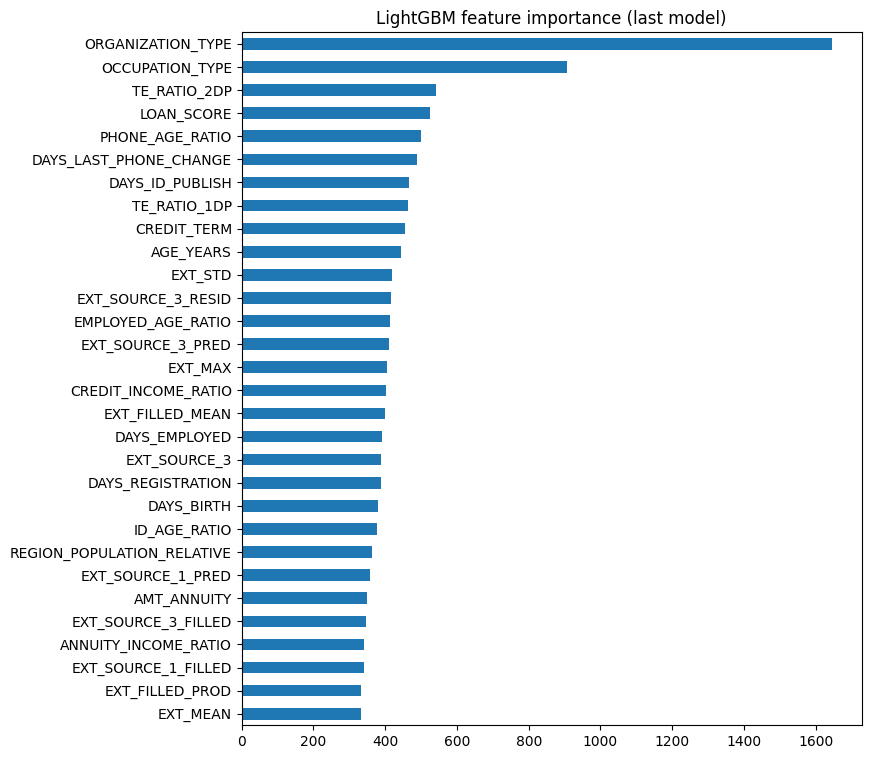

In [38]:
importance = pd.Series(model.feature_importances_, index=A_.columns).sort_values()
importance.tail(30).plot(kind="barh", figsize=(8, 9), title="LightGBM feature importance (last model)")

## Step 8: CatBoost, 5-fold CV
CatBoost is especially good with categorical features. It target-encodes them itself with **ordered target statistics**, which is leak-safe by design.
Here it gets the normal features, **the loan-product keys from Step 5 as categories**, and **the same repeat-customer features** that LightGBM used in each fold.

This is the slowest step: roughly 30–45 minutes on Colab's free CPU.

In [39]:
X_cb = pd.concat([X, cat_keys_train], axis=1)
X_test_cb = pd.concat([X_test, cat_keys_test], axis=1)
cb_cats = cat_cols + list(cat_keys.columns)
for c in cb_cats:
    X_cb[c] = X_cb[c].astype(object).fillna("NA").astype(str)
    X_test_cb[c] = X_test_cb[c].astype(object).fillna("NA").astype(str)

oof_cat = np.zeros(len(X))
pred_cat = np.zeros(len(X_test))

for fold, (tr_idx, va_idx) in enumerate(folds):
    link_tr, link_va, link_te = link_by_fold[fold]
    A_cb = side_by_side(X_cb.iloc[tr_idx], link_tr)
    B_cb = side_by_side(X_cb.iloc[va_idx], link_va)
    T_cb = side_by_side(X_test_cb, link_te)
    model_cb = CatBoostClassifier(
        iterations=10000, learning_rate=0.06, depth=6, l2_leaf_reg=5,
        eval_metric="AUC", random_seed=SEED, od_type="Iter", od_wait=300,
        verbose=0, thread_count=-1,
    )
    model_cb.fit(
        Pool(A_cb, y[tr_idx], cat_features=cb_cats),
        eval_set=Pool(B_cb, y[va_idx], cat_features=cb_cats),
        use_best_model=True,
    )
    oof_cat[va_idx] = model_cb.predict_proba(B_cb)[:, 1]
    pred_cat += model_cb.predict_proba(Pool(T_cb, cat_features=cb_cats))[:, 1] / len(folds)
    print(f"Fold {fold}: AUC = {roc_auc_score(y[va_idx], oof_cat[va_idx]):.5f} (trees: {model_cb.get_best_iteration()})")

print(f"\nCatBoost CV AUC = {roc_auc_score(y, oof_cat):.5f}")

Fold 0: AUC = 0.76855 (trees: 792)
Fold 1: AUC = 0.77319 (trees: 869)
Fold 2: AUC = 0.77542 (trees: 965)
Fold 3: AUC = 0.76792 (trees: 678)
Fold 4: AUC = 0.77279 (trees: 1194)

CatBoost CV AUC = 0.77151


## Step 9: Blend the two models
A weighted average of the two models' predictions. The weight was chosen on the out-of-fold (CV) predictions: **50% LightGBM + 50% CatBoost**.

In [40]:
for w in [0.0, 0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 1.0]:
    print(f"CatBoost weight {w:.2f}: CV AUC = {roc_auc_score(y, (1 - w) * oof_lgb + w * oof_cat):.5f}")

W_CAT = 0.5
oof_blend = (1 - W_CAT) * oof_lgb + W_CAT * oof_cat
pred = (1 - W_CAT) * pred_lgb + W_CAT * pred_cat
print(f"\nFinal blend CV AUC = {roc_auc_score(y, oof_blend):.5f}")

CatBoost weight 0.00: CV AUC = 0.77143
CatBoost weight 0.30: CV AUC = 0.77275
CatBoost weight 0.40: CV AUC = 0.77293
CatBoost weight 0.45: CV AUC = 0.77298
CatBoost weight 0.50: CV AUC = 0.77299
CatBoost weight 0.55: CV AUC = 0.77297
CatBoost weight 0.60: CV AUC = 0.77293
CatBoost weight 0.70: CV AUC = 0.77276
CatBoost weight 1.00: CV AUC = 0.77151

Final blend CV AUC = 0.77299


## Step 10: Save the submission (do not change this format)

In [41]:
sample_sub["TARGET"] = pred
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)
sample_sub.to_csv(output_dir / "submission.csv", index=False)
print(sample_sub.shape)
sample_sub.head()

(61500, 2)


,SK_ID_CURR,TARGET
0,171202,0.025044
1,171203,0.264383
2,171204,0.149093
3,171205,0.090355
4,171206,0.221336


## Step 11: Save this notebook as a ZIP (required for Honors/Outstanding)
1. Save the notebook first (**Ctrl+S / Cmd+S**).
2. Run the cell below.
3. Download `my_model_v6.zip` and upload it on Omnicampus under **Competition (.zip)**.

In [42]:
import zipfile
notebook_filename = "my_model_v6.ipynb"
zip_filename = "my_model_v6.zip"
notebook_path = current_dir / notebook_filename
if notebook_path.exists():
    with zipfile.ZipFile(current_dir / zip_filename, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(notebook_path, arcname=notebook_filename)
    print("Created", current_dir / zip_filename)
else:
    print(f"Could not find {notebook_filename} in {current_dir}")

Created /content/drive/MyDrive/competition/my_model_v6.zip
